In [1]:
import numpy as np
import xarray as xr
import scipy as sp
import emcee
import corner
import logging
import matplotlib.pyplot as plt
import cdflib.xarray

from tqdm import tqdm
from numba import njit, prange
from scipy.spatial import cKDTree
from scipy.special import ellipe

import functions.load_routines as load
from functions.spc_current_to_rdf import derive_reduced_vdf
from functions.data_preprocessing import xarray_clean_variable as clean
from functions.misc_functions import hampel_filter2
from functions.smooth_spc_data import smooth_spc_resample
from functions.spc_flow_angle_correction import spc_flow_angle_correction_1d_fast
from support_functions.gen_spc_uncert_map_2d import gen_uncertainty_map_with_bias

import functions.spc_processing_pipeline as spp

from functions.spc_spike_removal import despike_dataset
import functions.spc_calc_anisotropy as spca

In [2]:
def get_split_log_normal_pdf(mu_log, dp_log, dm_log, x_log):
    """
    Mathematical generator for the Split-Normal probability density function.
    """
    C = np.sqrt(2.0 / np.pi) / (dp_log + dm_log)
    pdf_log = np.zeros_like(x_log)
    
    mask_left = x_log < mu_log
    pdf_log[mask_left] = C * np.exp(-0.5 * ((x_log[mask_left] - mu_log) / dm_log)**2)
    
    mask_right = x_log >= mu_log
    pdf_log[mask_right] = C * np.exp(-0.5 * ((x_log[mask_right] - mu_log) / dp_log)**2)
    
    return pdf_log

def plot_tug_of_war(alpha_true_med, alpha_true_low, alpha_true_high, 
                    alpha_eff_x_med, hw_dp_log_x, hw_dm_log_x,
                    alpha_eff_y_med, hw_dp_log_y, hw_dm_log_y):
    """
    Overlays the final Bayesian consensus (True Alpha) against both 
    empirical measurements (X and Y) and their hardware expectations.
    """
    # 1. MCMC Posterior Parameters (The Final Consensus)
    mu_log_true = np.log10(alpha_true_med)
    dp_log_true = np.log10(alpha_true_high) - mu_log_true
    dm_log_true = mu_log_true - np.log10(alpha_true_low)
    
    # 2. Empirical Measurement Parameters (The Raw Data Likelihoods)
    mu_log_eff_x = np.log10(alpha_eff_x_med)
    mu_log_eff_y = np.log10(alpha_eff_y_med)
    
    # 3. Create a shared x-axis covering the extremes of ALL distributions
    x_min_log = min(mu_log_true - 4 * dm_log_true, 
                    mu_log_eff_x - 4 * hw_dm_log_x, 
                    mu_log_eff_y - 4 * hw_dm_log_y)
    
    x_max_log = max(mu_log_true + 4 * dp_log_true, 
                    mu_log_eff_x + 4 * hw_dp_log_x, 
                    mu_log_eff_y + 4 * hw_dp_log_y)
    
    x_log = np.linspace(x_min_log, x_max_log, 3000)
    x_linear = 10**x_log
    
    # 4. Generate the PDFs in Log Space
    pdf_log_true  = get_split_log_normal_pdf(mu_log_true, dp_log_true, dm_log_true, x_log)
    pdf_log_eff_x = get_split_log_normal_pdf(mu_log_eff_x, hw_dp_log_x, hw_dm_log_x, x_log)
    pdf_log_eff_y = get_split_log_normal_pdf(mu_log_eff_y, hw_dp_log_y, hw_dm_log_y, x_log)
    
    # 5. Transform to Linear Space (divide by x * ln(10) to preserve probability area)
    jacobian = x_linear * np.log(10)
    pdf_lin_true  = pdf_log_true / jacobian
    pdf_lin_eff_x = pdf_log_eff_x / jacobian
    pdf_lin_eff_y = pdf_log_eff_y / jacobian

    # ==========================================
    # PLOTTING
    # ==========================================
    fig, ax = plt.subplots(figsize=(12, 7))
    
    # Plot Empirical Y-Measurement (Pulls Left)
    ax.plot(x_linear, pdf_lin_eff_y, color='dodgerblue', lw=2, linestyle='-', 
            label='Simulated Y-Plane Spread')
    ax.fill_between(x_linear, pdf_lin_eff_y, color='dodgerblue', alpha=0.15)
    ax.axvline(alpha_eff_y_med, color='dodgerblue', linestyle='--', alpha=0.8,
               label=f'Measured Y-Anisotropy: {alpha_eff_y_med:.2f}')
    
    # Plot Empirical X-Measurement (Pulls Right)
    ax.plot(x_linear, pdf_lin_eff_x, color='darkorange', lw=2, linestyle='-', 
            label='Simulated X-Plane Spread')
    ax.fill_between(x_linear, pdf_lin_eff_x, color='darkorange', alpha=0.15)
    ax.axvline(alpha_eff_x_med, color='darkorange', linestyle='--', alpha=0.8,
               label=f'Measured X-Anisotropy: {alpha_eff_x_med:.2f}')
    
    # Plot Final MCMC Posterior (The True Consensus)
    ax.plot(x_linear, pdf_lin_true, color='darkgreen', lw=2.5, 
            label='Final Bayesian Posterior (Consensus)')
    ax.fill_between(x_linear, pdf_lin_true, color='darkgreen', alpha=0.4)
    ax.axvline(alpha_true_med, color='darkgreen', linestyle='-', lw=2,
               label=f'True Consensus: {alpha_true_med:.2f}')
    
    # Formatting
    ax.set_title('Bayesian Tug-of-War: True Anisotropy Triangulated from Noisy X & Y Measurements', fontsize=15)
    ax.set_xlabel(r'Temperature Anisotropy ($T_\perp / T_\parallel$)', fontsize=13)
    ax.set_ylabel('Probability Density', fontsize=13)
    
    # Use log scale for the x-axis
    ax.set_xscale('log')
    from matplotlib.ticker import ScalarFormatter
    ax.xaxis.set_major_formatter(ScalarFormatter())
    
    # Set dynamic limits to frame the active curves perfectly
    ax.set_xlim(10**(x_min_log*0.95), 10**(x_max_log*1.05))
    
    # Place legend neatly out of the way
    ax.legend(fontsize=11, loc='upper right', bbox_to_anchor=(1.0, 1.0))
    ax.grid(True, alpha=0.3, which='both', linestyle='--')
    
    plt.tight_layout()
    plt.show()

# Okay look at wha the true reported anisotropy is telling you. 
def plot_split_log_normal(alpha_median, alpha_lower, alpha_upper):
    """
    Plots the Split-Log-Normal distribution for a given median and its 1-sigma bounds.
    
    Parameters:
    -----------
    alpha_median : float
        The reported median anisotropy (e.g., 2.512)
    alpha_lower : float
        The reported absolute lower bound (e.g., 2.359)
    alpha_upper : float
        The reported absolute upper bound (e.g., 2.656)
    """
    # 1. Convert physical linear bounds into Log10 space parameters
    mu_log = np.log10(alpha_median)
    log_lower = np.log10(alpha_lower)
    log_upper = np.log10(alpha_upper)
    
    # Calculate the strictly positive standard deviations in log space
    delta_minus_log = mu_log - log_lower
    delta_plus_log = log_upper - mu_log
    
    # 2. Generate the x-axis grid in Log10 space (± 4 sigma for a nice smooth tail)
    x_log = np.linspace(mu_log - 4 * delta_minus_log, mu_log + 4 * delta_plus_log, 1000)
    
    # 3. Calculate the Split-Normal PDF in Log Space
    # Normalization constant ensuring the total area = 1.0
    C = np.sqrt(2.0 / np.pi) / (delta_plus_log + delta_minus_log)
    
    pdf_log = np.zeros_like(x_log)
    
    # Left half (using delta_minus)
    mask_left = x_log < mu_log
    pdf_log[mask_left] = C * np.exp(-0.5 * ((x_log[mask_left] - mu_log) / delta_minus_log)**2)
    
    # Right half (using delta_plus)
    mask_right = x_log >= mu_log
    pdf_log[mask_right] = C * np.exp(-0.5 * ((x_log[mask_right] - mu_log) / delta_plus_log)**2)
    
    # 4. Transform to physical linear space
    # To correctly transform a PDF from log(x) to x, we must divide by x * ln(10)
    # This preserves the area under the curve!
    x_linear = 10**x_log
    pdf_linear = pdf_log / (x_linear * np.log(10))
    
    # ==========================================
    # PLOTTING
    # ==========================================
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # --- Plot 1: Log-Space (The mathematical view) ---
    ax1 = axes[0]
    ax1.plot(x_log, pdf_log, color='navy', lw=2)
    ax1.axvline(mu_log, color='red', linestyle='--', label=f'Median: {mu_log:.3f}')
    ax1.axvspan(log_lower, log_upper, color='red', alpha=0.2, label=r'1-$\sigma$ Bounds')
    
    ax1.set_title('Split-Normal Distribution\n(Log10 Space)', fontsize=14)
    ax1.set_xlabel(r'$\log_{10}(\alpha_{true})$', fontsize=12)
    ax1.set_ylabel('Probability Density', fontsize=12)
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # --- Plot 2: Linear-Space (The physical view) ---
    ax2 = axes[1]
    ax2.plot(x_linear, pdf_linear, color='darkgreen', lw=2)
    ax2.axvline(alpha_median, color='red', linestyle='--', label=f'Median: {alpha_median:.3f}')
    ax2.axvspan(alpha_lower, alpha_upper, color='red', alpha=0.2, label=r'1-$\sigma$ Bounds')
    
    ax2.set_title('Split-Log-Normal Distribution\n(Physical Linear Space)', fontsize=14)
    ax2.set_xlabel(r'True Temperature Anisotropy ($T_\perp / T_\parallel$)', fontsize=12)
    ax2.set_ylabel('Probability Density', fontsize=12)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

<h2>Begin the Main Code!</h2>

In [3]:
# Configuration
config = {
    'fit_seconds':4,
    'smooth_seconds': None,
    'spc_mode': 'peak_track',
    'no_weights': None,
    'win_max': False,
    'min_flux': 0.37,
    'flow_correction': True,
    'avg_bfield': False,
    'data_vars': {
        'spc' : ['l2i', 'l3i'],
        'fields' : 'mag_SC_4_Sa_per_Cyc',
        # 'spi_sf00' : ['L3']
    },
    'credentials': None, 
    'uncert_map': gen_uncertainty_map_with_bias(), 
    'gen_flag': True,
    'OFFLINE': True, 
    'likelihood_method': "T",
    'plot_diagnostics': True
}

# Top 5 events
dates_to_process_list = ['2024-03-26', '2023-09-23', '2024-06-25', '2024-12-20', '2024-09-25']
dates_to_process = [dates_to_process_list[2]]

year, month, day = dates_to_process[0].split('-') 

date_str = dates_to_process[0]
config_dict = config

# Create the time range to load in the data
tstart = f"{date_str}T00:00:00"
tend   = f"{date_str}T23:59:59"
range_desc = "Full Day"
slice_things = False

# Unpack all the config information.
fit_seconds = config_dict['fit_seconds']
smooth_seconds = config_dict['smooth_seconds']
spc_mode = config_dict['spc_mode']
no_weights = config_dict['no_weights']
win_max = config_dict['win_max']
min_flux = config_dict['min_flux']
avg_bfield = config_dict['avg_bfield']
data_vars = config_dict['data_vars']
credentials = config_dict['credentials']
uncert_map = config_dict['uncert_map']
gen_flag   = config_dict['gen_flag']
OFFLINE = config_dict['OFFLINE']
likelihood_method = config_dict['likelihood_method']

trange = [tstart, tend]

init_ds = spp.initialize_fitting_data(trange, data_vars, smooth_seconds=smooth_seconds, mode=spc_mode, credentials=None, OFFLINE=OFFLINE)

if gen_flag:
    flag = init_ds.general_flag.data
    init_ds = init_ds.isel(epoch = np.where(flag == 0)[0])
    print(f"Dropping data with general_flag != 0! (Total Dropped)/Total = {len(flag) - np.sum(flag == 0)}/{len(flag)}")

if slice_things:
    print(f"Slicing data to range: {tstart} -- {tend}")
    init_ds = init_ds.sel(epoch=slice(tstart, tend))
    
if init_ds.epoch.size == 0:
    print(f"No data found in range {tstart} to {tend}. Skipping.")

pa_flag = spp.get_pA_flags(init_ds).rename({'epoch': 'time'})

support_vars = spp.SUPPORT_VARS

fit_steps = np.timedelta64(np.datetime64(tend, 'ns') - np.datetime64(tstart))/np.timedelta64(fit_seconds, 's')
fit_time  = np.datetime64(tstart, 'ns') + np.arange(fit_steps+1)*np.timedelta64(fit_seconds, 's')
windows = np.squeeze(np.dstack([fit_time[0:-1:1], fit_time[1::1]]))

subset = init_ds.drop_vars([v for v in init_ds.data_vars if v not in ["a_current", "b_current", "c_current", "d_current"]])
ds_groupby = subset.groupby(['epoch', 'mv_lo']).mean(skipna=True)
binned_ds = ds_groupby.groupby_bins('epoch', fit_time).mean(skipna=True)

midpoints = binned_ds.epoch_bins.to_index().mid
binned_ds = binned_ds.assign_coords(epoch=('epoch_bins', midpoints))
binned_ds = binned_ds.swap_dims({"epoch_bins":"epoch"}).drop_vars("epoch_bins")

pa_flag = spp.get_pA_flags(binned_ds).rename({'epoch': 'time'})

Loading from local data directory: /home/michael/Research/PSP_Temp_Anisotropy/psp_data

 /home/michael/Research/PSP_Temp_Anisotropy/psp_data/sweap/spc/l3/l3i/2024/psp_swp_spc_l3i_20240625_v02.cdf 

Loading in the l2 data
Despiking dataset!
Dropping data with general_flag != 0! (Total Dropped)/Total = 1021/176206


09-Nov-26 14:28:16: /home/michael/Research/PSP_Temp_Anisotropy/functions/spc_processing_pipeline.py:242: RuntimeWarning: All-NaN axis encountered
  max_dict[f'{key}_max'] = np.nanmax(init_ds[f'{key}_current'], axis=1)

09-Nov-26 14:28:17: /home/michael/Research/PSP_Temp_Anisotropy/functions/spc_processing_pipeline.py:243: RuntimeWarning: All-NaN slice encountered
  med_dict[f'{key}_med'] = np.nanmedian(init_ds[f'{key}_current'], axis=1)



In [4]:
ds = init_ds
uncertainty_map = uncert_map
method = 'Bayesian_MCMC_5D_NCP'
likelihood_type = 'T'

# From the input dataset, extract all the key supporting information.
time = spca.get_data(ds, "epoch")

peak_az = spca.get_data(ds, "peak_azimuth")      # Peak flow angle values
peak_el = spca.get_data(ds, "peak_elevation")    

vx = spca.get_data(ds, "vel_x")
vy = spca.get_data(ds, "vel_y")
vz = -spca.get_data(ds, "vel_mid")               # Add the negative to rectify sign

vz_hi = -spca.get_data(ds, "vel_hi")             
vz_lo = -spca.get_data(ds, "vel_lo")

bvec = np.atleast_2d(spca.get_data(ds, "b_vec")) 

# Extract the plate currents and the reduced distribution function
ia_curr = spca.get_data(ds, "a_current")
ib_curr = spca.get_data(ds, "b_current")
ic_curr = spca.get_data(ds, "c_current")
id_curr = spca.get_data(ds, "d_current")

itot = ia_curr + ib_curr + ic_curr + id_curr

# Extract the standard deviations from the dataset
ia_std = spca.get_data(ds, "a_current_DELTA_VAR")
ib_std = spca.get_data(ds, "b_current_DELTA_VAR")
ic_std = spca.get_data(ds, "c_current_DELTA_VAR")
id_std = spca.get_data(ds, "d_current_DELTA_VAR")

# Extract the modulator voltage uncertanties
mv_lo = spca.get_data(ds, "mv_lo")
mv_hi = spca.get_data(ds, "mv_hi")
sig_mv_lo = spca.get_data(ds, "mv_lo_DELTA_VAR")
sig_mv_hi = spca.get_data(ds, "mv_hi_DELTA_VAR")

# Get the reduced distribution function
rdf = spca.get_data(ds, "rdf")

# Get the flow angles
azimuth    = spca.get_data(ds, "azimuth")
elevation  = spca.get_data(ds, "elevation")

In [5]:
weights_rdf  = rdf/np.nanmax(rdf, axis=1)[:,None]
weights_itot = itot/np.nanmax(itot, axis=1)[:,None]

mask_weights = spca.get_contiguous_peak_mask(weights_itot, min_flux)

delta_vz = vz_hi - vz_lo

integral_weights = np.where(mask_weights, rdf, 0.0)

sum_weights = np.sum(integral_weights, axis=1)
sum_weights = np.where(sum_weights == 0, np.nan, sum_weights)

u_z = (np.sum(np.where(mask_weights, vz * integral_weights, 0.0), axis=1)/ sum_weights)

valid_rows = np.any(mask_weights, axis=1)   # Rows with at least one valid weight
max_idx = np.zeros(rdf.shape[0], dtype=int)
max_idx[valid_rows] = np.nanargmax(np.where(mask_weights[valid_rows], rdf[valid_rows], np.nan), axis=1)
row_idx = np.arange(rdf.shape[0])

u_x = -u_z * np.tan(np.radians(azimuth[row_idx, max_idx]))
u_y = -u_z * np.tan(-np.radians(elevation[row_idx, max_idx]))

uvec = np.squeeze(np.dstack([u_x, u_y, u_z]))

nvec = bvec / np.linalg.norm(bvec, axis=1)[:,None]

vz_geo_center = (vz_hi + vz_lo) / 2.0
vz_bias_sq = (vz - vz_geo_center)**2
vz_quant_var = ((vz_hi - vz_lo)**2) / 12.0
vz_hw_var = spca.calc_vz_hardware_variance(mv_lo, mv_hi, sig_mv_lo, sig_mv_hi)
vz_var_tot = vz_quant_var + vz_bias_sq + vz_hw_var

In [6]:
base_dict = {
        'vx': vx, 'vy': vy, 'vz': vz,
        'rdf': rdf, 'weights_itot': weights_itot, 'weights_rdf': weights_rdf,
        'mask': mask_weights, 'peak_az': peak_az, 'peak_el': peak_el,
        'bvec': bvec, 'nvec': nvec, 'uvec': uvec,
        'itot': itot, 'ia_curr': ia_curr, 'ib_curr': ib_curr,
        'ic_curr': ic_curr, 'id_curr': id_curr,
        'ia_std': ia_std, 'ib_std': ib_std, 'ic_std': ic_std, 'id_std': id_std,
        'vz_var': vz_var_tot, 'time': time,
    }

static_length = vx.shape[1]
nan_template = spca.BASE_NAN_TEMPLATE.copy()
all_results = []

In [7]:
middle_times = windows[:,0] + (windows[:,1] - windows[:,0]) / 2

t0, t1 = windows[15899]


print("Checkpoint t0, t1: ", t0, t1)

idx_start = np.searchsorted(time, np.datetime64(t0)) 
idx_end = np.searchsorted(time, np.datetime64(t1))

print(f"Index range for time window {t0} to {t1}: {idx_start} to {idx_end}")

block_time = t0 + (t1 - t0)/2

bvec_slice = base_dict['bvec'][idx_start:idx_end]
valid_bvec = ~np.all(np.isnan(bvec_slice), axis=1)

block = {key: val[idx_start:idx_end][valid_bvec] for key, val in base_dict.items()}

vz_shifted = block['vz'] - block['uvec'][:, 2][:, None]
block_nvec_avg = np.nanmean(block['nvec'], axis=0)
block_nvec_avg /= np.linalg.norm(block_nvec_avg)

block_bvec_to_save = np.nanmean(block['bvec'], axis=0)
block_bvec_var = np.nanvar(block['bvec'], axis=0)
b_var_tot = np.nansum(block_bvec_var)

xangle = np.degrees(np.arctan(block_nvec_avg[0] / block_nvec_avg[2]))
yangle = np.degrees(np.arctan(block_nvec_avg[1] / block_nvec_avg[2]))

geom_ok_x = (np.abs(xangle) >= 4.0) & (np.abs(xangle) <= 89.0)
geom_ok_y = (np.abs(yangle) >= 4.0) & (np.abs(yangle) <= 89.0)

mask_core = block['mask']
rel_itot  = block['weights_itot']

I_x_pos = block['ia_curr'] + block['id_curr']  # A + D (+x)
I_x_neg = block['ib_curr'] + block['ic_curr']  # B + C (-x)

I_y_pos = block['ia_curr'] + block['ib_curr']  # A + B (+y)
I_y_neg = block['ic_curr'] + block['id_curr']  # C + D (-y)

# Reject reverse-biased / dead channels
plates_positive = (
    (block['ia_curr'] > -0.2) & (block['ib_curr'] > -0.2) &
    (block['ic_curr'] > -0.2) & (block['id_curr'] > -0.2)
)

itot_floor = 5.0
rel_itot_floor = 0.5
pair_floor = 5.0

current_ok = (block['itot'] >= itot_floor) & (rel_itot >= rel_itot_floor) & plates_positive

valid_mask_x = mask_core & current_ok & plates_positive & (I_x_pos >= pair_floor) & (I_x_neg >= pair_floor)
valid_mask_y = mask_core & current_ok & plates_positive & (I_y_pos >= pair_floor) & (I_y_neg >= pair_floor)

valid_mask_joint = valid_mask_x & valid_mask_y

n_joint = np.sum(valid_mask_joint)
n_x_only = np.sum(valid_mask_x)
n_y_only = np.sum(valid_mask_y)

n_samples = block['time'].size

data_vars = nan_template.copy()
data_vars.update({
    "Nx": block_nvec_avg[0], "Ny": block_nvec_avg[1], "Nz": block_nvec_avg[2],
    "Bx": block_bvec_to_save[0], "By": block_bvec_to_save[1], "Bz": block_bvec_to_save[2],
    "B_var_x": block_bvec_var[0], "B_var_y": block_bvec_var[1], "B_var_z": block_bvec_var[2],
    "B_var_tot": b_var_tot, "B_x_flow_angle": xangle, "B_y_flow_angle": yangle,
    "peak_azimuth": np.nanmean(block['peak_az']).item(),
    "peak_elevation": np.nanmean(block['peak_el']).item(),
    "n_samples": n_samples,
})

min_fit_points = 3


if n_joint >= min_fit_points and geom_ok_x and geom_ok_y and method in ("Bayesian_MCMC_5D_NCP", "Bayesian_MCMC_NCP"):
    print(f"Performing 5D joint fit for time window {t0} to {t1} with {n_joint} valid points.")
    # --- 5D JOINT CONSENSUS FIT ---
    valid_idx = valid_mask_joint
    block['weight_fits'] = np.ones(n_joint)

    vx_fit = (block['vx'] - block['uvec'][:, 0][:, None])[valid_idx]
    vy_fit = (block['vy'] - block['uvec'][:, 1][:, None])[valid_idx]
    vz_fit = (block['vz'] - block['uvec'][:, 2][:, None])[valid_idx]
    vz_var = block['vz_var'][valid_idx]

    vzbx_fit = (vz_shifted * block['nvec'][:, 0][:, None])[valid_idx]
    vzby_fit = (vz_shifted * block['nvec'][:, 1][:, None])[valid_idx]

    update_dict, samples, var_x_array, var_y_array = spca._run_bayesian_pipeline_5d_ncp(
        block, valid_idx, vzbx_fit, vx_fit, vzby_fit, vy_fit, vz_var,
        block_nvec_avg, uncertainty_map, xangle, yangle, static_length,
        likelihood_type=likelihood_type
    )
    data_vars.update(update_dict)

elif n_x_only >= min_fit_points and geom_ok_x and method in ("Bayesian_MCMC_5D_NCP", "Bayesian_MCMC_NCP"):
    print(f"Performing 3D X-only fit for time window {t0} to {t1} with {n_x_only} valid points.")
    # --- 3D X-ONLY FALLBACK ---
    valid_idx = valid_mask_x
    block['weight_fits'] = np.ones(n_x_only)

    vx_fit = (block['vx'] - block['uvec'][:, 0][:, None])[valid_idx]
    vy_fit = np.array([])  # Empty so plotting function knows Y is unmeasured
    vz_fit = (block['vz'] - block['uvec'][:, 2][:, None])[valid_idx]
    vz_var = block['vz_var'][valid_idx]

    vzbx_fit = (vz_shifted * block['nvec'][:, 0][:, None])[valid_idx]
    vzby_fit = np.array([])

    update_dict, samples, var_x_array, var_y_array = spca._run_bayesian_pipeline_3d_ncp(
        block, valid_idx, vzbx_fit, vx_fit, vz_var,
        block_nvec_avg, uncertainty_map, xangle, static_length, tag='x',
        likelihood_type=likelihood_type
    )
    data_vars.update(update_dict)

elif n_y_only >= min_fit_points and geom_ok_y and method in ("Bayesian_MCMC_5D_NCP", "Bayesian_MCMC_NCP"):
    print(f"Performing 3D Y-only fit for time window {t0} to {t1} with {n_y_only} valid points.")
    # --- 3D Y-ONLY FALLBACK ---
    valid_idx = valid_mask_y
    block['weight_fits'] = np.ones(n_y_only)

    vx_fit = np.array([])  # Empty so plotting function knows X is unmeasured
    vy_fit = (block['vy'] - block['uvec'][:, 1][:, None])[valid_idx]
    vz_var = block['vz_var'][valid_idx]
    vz_fit = (block['vz'] - block['uvec'][:, 2][:, None])[valid_idx]

    vzbx_fit = np.array([])
    vzby_fit = (vz_shifted * block['nvec'][:, 1][:, None])[valid_idx]

    update_dict, samples, var_x_array, var_y_array = spca._run_bayesian_pipeline_3d_ncp(
        block, valid_idx, vzby_fit, vy_fit, vz_var,
        block_nvec_avg, uncertainty_map, yangle, static_length, tag='y',
        likelihood_type=likelihood_type
    )
    data_vars.update(update_dict)

else:
    # Neither plane is statistically or geometrically viable
    nan_rec = nan_template.copy()
    nan_rec['time'] = block_time
    all_results.append(nan_rec)
    
data_vars['time'] = block_time
all_results.append(data_vars)

Checkpoint t0, t1:  2024-06-25T17:39:56.000000000 2024-06-25T17:40:00.000000000
Index range for time window 2024-06-25T17:39:56.000000000 to 2024-06-25T17:40:00.000000000: 124880 to 124889
Performing 5D joint fit for time window 2024-06-25T17:39:56.000000000 to 2024-06-25T17:40:00.000000000 with 53 valid points.


Text(0.5, 1.05, '5D MCMC Posterior: 2024-06-25T17:39:58.000000000')

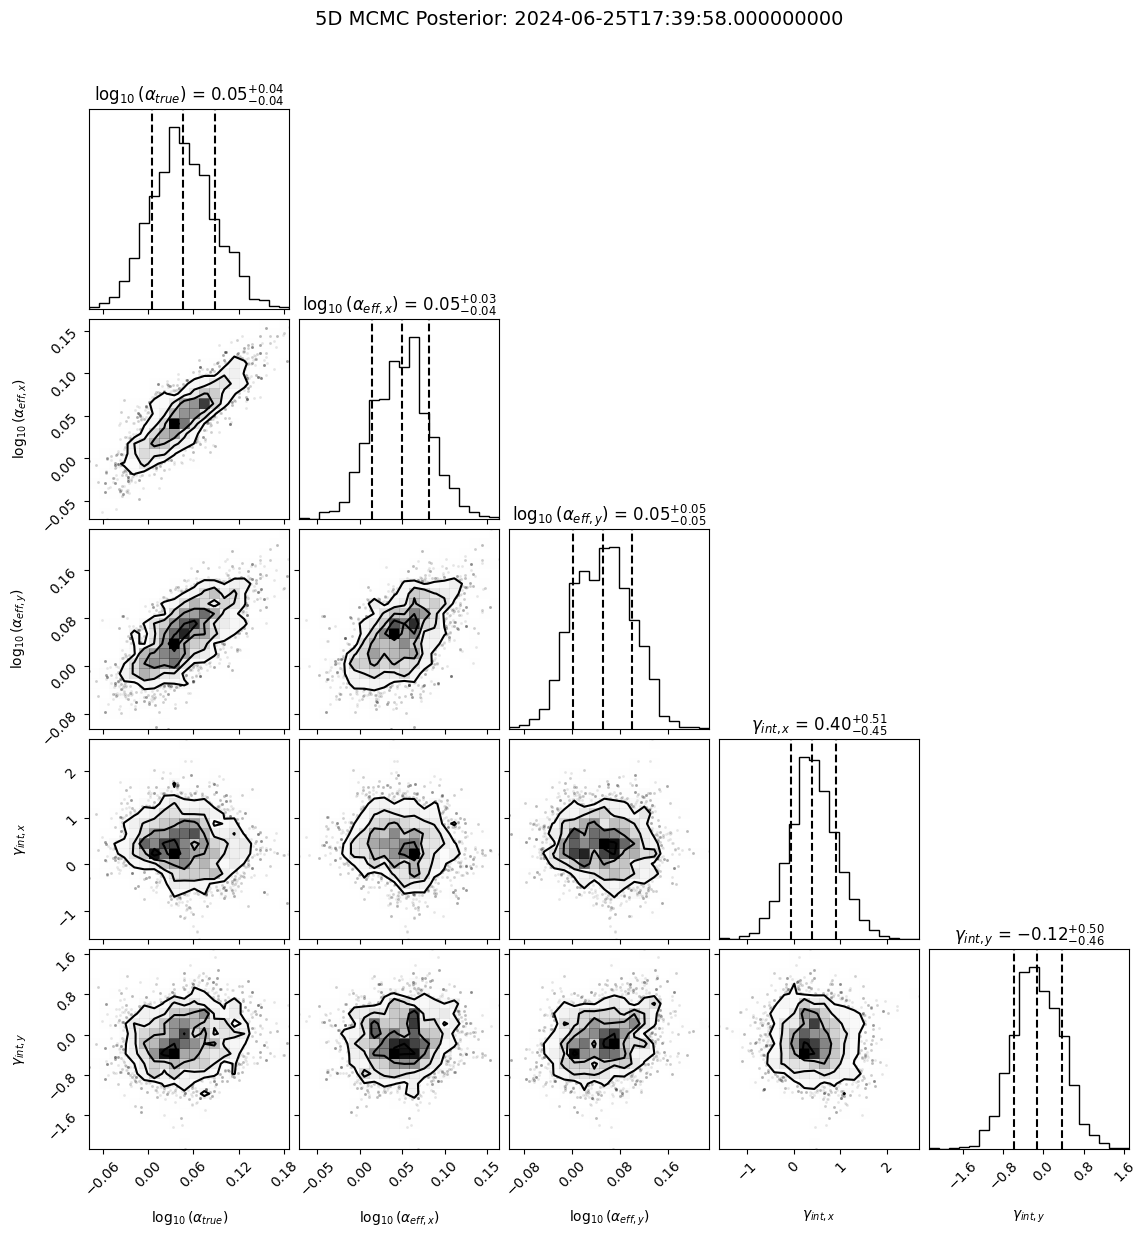

In [8]:
# Transform only the Alpha columns to log10
plot_samples = np.copy(samples)
plot_samples[:, 0:3] = np.log10(plot_samples[:, 0:3])

# Update labels for 5D
labels = [r"$\log_{10}(\alpha_{true})$", r"$\log_{10}(\alpha_{eff,x})$", 
          r"$\log_{10}(\alpha_{eff,y})$", r"$\gamma_{int,x}$", r"$\gamma_{int,y}$"]
            
fig = corner.corner(plot_samples, labels=labels, 
                    quantiles=[0.16, 0.5, 0.84], show_titles=True)
plt.suptitle(f"5D MCMC Posterior: {block_time}", y=1.05, fontsize=14)

In [9]:
def calc_slope_from_anisotropy(alpha, bz):
    term = 1.0 - alpha
    numerator = term * bz
    denominator = 1.0 - term * (1.0 - bz**2)
    
    # Safely handle both scalar and array inputs to prevent divide-by-zero
    if np.isscalar(denominator):
        if np.abs(denominator) < 1e-12:
            return np.nan
        return numerator / denominator
    else:
        # Array safe division
        M = np.full_like(denominator, np.nan, dtype=float)
        valid = np.abs(denominator) >= 1e-12
        M[valid] = numerator[valid] / denominator[valid]
        return M

In [10]:
xlim_ts   = np.datetime64(f'{dates_to_process[0]}T17:25:00') 
xlim_tend = np.datetime64(f'{dates_to_process[0]}T18:20:00')
time_of_interest = np.datetime64(f'{dates_to_process[0]}T17:40:00')

test_idx = np.nanargmin(np.abs(middle_times - time_of_interest))

init_ds_sel = init_ds.sel(epoch=slice(xlim_ts, xlim_tend))

In [11]:
all_results

[{'Nx': np.float64(0.6393767105583607),
  'Ny': np.float64(-0.24360244881054802),
  'Nz': np.float64(0.7292840797172763),
  'Bx': np.float64(50.342230837754336),
  'By': np.float64(-19.177837056692887),
  'Bz': np.float64(57.41836124233013),
  'B_var_x': np.float64(1.9662456568373297),
  'B_var_y': np.float64(3.8283450231637466),
  'B_var_z': np.float64(0.36759143617755147),
  'B_var_tot': np.float64(6.162182116178628),
  'B_x_flow_angle': np.float64(41.24163828784553),
  'B_y_flow_angle': np.float64(-18.47084368981793),
  'peak_azimuth': -0.50063157081604,
  'peak_elevation': 0.12758558988571167,
  'T_ani_avg': np.float64(1.1107993814033126),
  'T_ani_avg_delta_plus': np.float64(0.11637517989408952),
  'T_ani_avg_delta_minus': np.float64(0.09902773005922905),
  'T_ani_avg_delta_plus_log': np.float64(0.04327071477254784),
  'T_ani_avg_delta_minus_log': np.float64(0.040553122402008056),
  'T_ani_chi': np.float64(1.1219039527734571),
  'T_ani_chi_delta_plus': np.float64(0.083607461041729

In [12]:
block.keys()

dict_keys(['vx', 'vy', 'vz', 'rdf', 'weights_itot', 'weights_rdf', 'mask', 'peak_az', 'peak_el', 'bvec', 'nvec', 'uvec', 'itot', 'ia_curr', 'ib_curr', 'ic_curr', 'id_curr', 'ia_std', 'ib_std', 'ic_std', 'id_std', 'vz_var', 'time', 'weight_fits'])

09-Nov-26 14:28:49: /tmp/ipykernel_673923/2593649177.py:123: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  mesh_rdf = ax_rdf.pcolormesh(T_2d_full, vel_m_clean, plot_rdf,

09-Nov-26 14:28:49: /tmp/ipykernel_673923/2593649177.py:125: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  mesh_az  = ax_az.pcolormesh(T_2d_full, vel_m_clean, plot_az,

09-Nov-26 14:28:49: /tmp/ipykernel_673923/2593649177.py:127: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, i

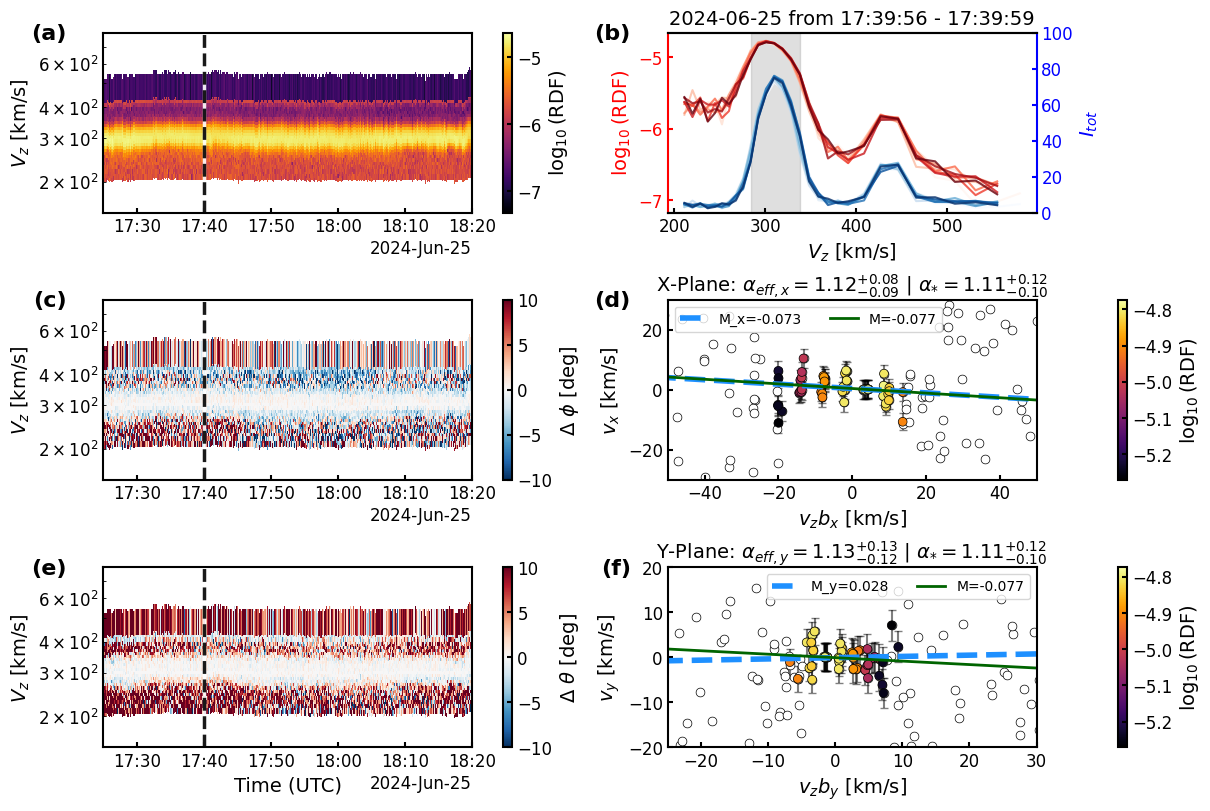

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import ListedColormap
import warnings

# ==========================================
# 1. SETUP PUBLICATION AESTHETICS
# ==========================================
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'axes.linewidth': 1.5,
    'xtick.major.width': 1.5,
    'ytick.major.width': 1.5,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
})

# ==========================================
# 2. EXTRACT FULL CONTEXT (init_ds)
# ==========================================
az_val_full = init_ds_sel.azimuth.values
el_val_full = init_ds_sel.elevation.values
rdf_val_full = init_ds_sel.rdf.values
itot_val_full = init_ds_sel.total_current.values
time_val_full = init_ds_sel.epoch.values
vel_m_full = init_ds_sel.vel_mid.values

# Track the peak across the entire dataset
col_index_full = np.nanargmax(rdf_val_full, axis=1)
row_index_full = np.arange(time_val_full.shape[0])
vel_peak_full = vel_m_full[row_index_full, col_index_full]

az_peak_full = az_val_full[row_index_full, col_index_full]
el_peak_full = el_val_full[row_index_full, col_index_full]

delta_az_full = az_val_full - az_peak_full[:, np.newaxis]
delta_el_full = el_val_full - el_peak_full[:, np.newaxis]

T_2d_full = np.broadcast_to(time_val_full[:, np.newaxis], (vel_m_full.shape[0], vel_m_full.shape[1]))

# --- Calculate the Gray Overlay for the Full Dataset (Using 0.3 threshold) ---
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    rdf_peak_val_full = np.nanmax(rdf_val_full, axis=1, keepdims=True)

valid_vel = np.isfinite(vel_m_full)

# The core is strictly where RDF > 30% of the peak
is_core = np.nan_to_num(rdf_val_full, nan=0.0) > (0.5 * np.nan_to_num(rdf_peak_val_full, nan=0.0))

# The gray mask should cover everywhere that has a valid velocity, EXCEPT the core
shade_mask = valid_vel & ~is_core

gray_overlay = np.where(shade_mask, 1.0, np.nan)
gray_cmap = ListedColormap(['gray'])

vz_s = block['vz'] - block['uvec'][:,2][:,None]
vzbx_plot = (vz_s * block['nvec'][:, 0][:, None])
vzby_plot = (vz_s * block['nvec'][:, 1][:, None])

a_x = all_results[-1]['T_ani_chi']
sig_px = all_results[-1]['T_ani_chi_delta_plus']
sig_mx = all_results[-1]['T_ani_chi_delta_minus']

a_y = all_results[-1]['T_ani_psi']
sig_py = all_results[-1]['T_ani_psi_delta_plus']
sig_my = all_results[-1]['T_ani_psi_delta_minus']

a_avg = all_results[-1]['T_ani_avg']
sig_p = all_results[-1]['T_ani_avg_delta_plus']
sig_m = all_results[-1]['T_ani_avg_delta_minus']

M_x = calc_slope_from_anisotropy(a_x, block_nvec_avg[0])
M_y = calc_slope_from_anisotropy(a_y, block_nvec_avg[1])

gam_x = all_results[-1]['gamma_chi']
gam_y = all_results[-1]['gamma_psi']

# ==========================================
# 3. BUILD THE FIGURE AND GRID
# ==========================================
fig = plt.figure(figsize=(12, 8), constrained_layout=True)
gs = gridspec.GridSpec(3, 2, width_ratios=[1.2, 1.2], figure=fig)

# Left Column Axes (Spectrograms context)
ax_rdf = fig.add_subplot(gs[0, 0])
ax_az  = fig.add_subplot(gs[1, 0], sharex=ax_rdf)
ax_el  = fig.add_subplot(gs[2, 0], sharex=ax_rdf)

# Right Column Axes (Specific block fit)
ax_stack = fig.add_subplot(gs[0, 1])
ax_xfit  = fig.add_subplot(gs[1, 1])
ax_yfit  = fig.add_subplot(gs[2, 1])

# ==========================================
# 4. PLOT LEFT COLUMN: FULL SPECTROGRAMS
# ==========================================
# --- 1. Create a safe, finite Y-coordinate grid to satisfy Matplotlib ---
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    # Get the average velocity for each bin across the entire sweep
    vel_col_means = np.nanmean(vel_m_full, axis=0)
    
# If an entire column is NaN, fallback to a simple linear space
if np.any(np.isnan(vel_col_means)):
    vel_col_means = np.linspace(np.nanmin(vel_m_full), np.nanmax(vel_m_full), vel_m_full.shape[1])

# Patch the missing Y coordinates with their column's average value
vel_fallback_2d = np.broadcast_to(vel_col_means, vel_m_full.shape)
vel_m_clean = np.where(np.isfinite(vel_m_full), vel_m_full, vel_fallback_2d)

# --- 2. Mask the data to punch out the blank space ---
plot_rdf = np.where(valid_vel & (rdf_val_full > 0), np.log10(rdf_val_full), np.nan)
plot_az  = np.where(valid_vel, delta_az_full, np.nan)
plot_el  = np.where(valid_vel, delta_el_full, np.nan)

# --- 3. Plot using the clean coordinates ---
mesh_rdf = ax_rdf.pcolormesh(T_2d_full, vel_m_clean, plot_rdf, 
                             cmap='inferno', shading='nearest', rasterized=True)
mesh_az  = ax_az.pcolormesh(T_2d_full, vel_m_clean, plot_az, 
                            cmap='RdBu_r', vmin=-10, vmax=10, shading='nearest', rasterized=True)
mesh_el  = ax_el.pcolormesh(T_2d_full, vel_m_clean, plot_el, 
                            cmap='RdBu_r', vmin=-10, vmax=10, shading='nearest', rasterized=True)

left_axes = [ax_rdf, ax_az, ax_el]
cbars = [mesh_rdf, mesh_az, mesh_el]
labels = [r'$\log_{10}$(RDF)', r'$\Delta$ $\phi$ [deg]', r'$\Delta$ $\theta$ [deg]']

for i, ax in enumerate(left_axes):
    # Apply overlay using the clean coordinates
    #if ax == ax_rdf:
        #ax.pcolormesh(T_2d_full, vel_m_clean, gray_overlay, 
        #          cmap=gray_cmap, vmin=0, vmax=1, alpha=0.6, shading='nearest', rasterized=True)
    
    # Plot the full peak track
    # ax.plot(time_val_full, vel_peak_full, linewidth=1.0, color='k', alpha=0.8, linestyle='--')
    
    # Mark the specific block time being fitted
    ax.axvline(block_time, color='white', linestyle='-', linewidth=2.5, alpha=0.9)
    ax.axvline(block_time, color='black', linestyle='--', linewidth=2.5, alpha=0.9)
    
    ax.set_yscale('log')
    ax.set_ylim([150, 800]) 
    ax.set_ylabel(r'$V_z$ [km/s]')
    fig.colorbar(cbars[i], ax=ax, label=labels[i], pad=0.02)
ax_el.set_xlabel('Time (UTC)')

# ==========================================
# 5. PLOT RIGHT COLUMN: BLOCK DIAGNOSTICS
# ==========================================
# --- Panel (b): Stacked Block RDFs ---
block_rdf = block['rdf']
block_vel = -block['vz']
block_times = block['time']

ax_stack2 = ax_stack.twinx()

fit_vz = block_vel[valid_idx]
v_span_min = np.nanmin(fit_vz)
v_span_max = np.nanmax(fit_vz)
ax_stack.axvspan(v_span_min, v_span_max, color='gray', alpha=0.25, zorder=0)

# Plot the VDFs specifically from the 'block'
colors = plt.cm.viridis(np.linspace(0, 1, len(block_times)))

color1 = plt.cm.Reds(np.linspace(0, 1, len(block_times)))
color2 = plt.cm.Blues(np.linspace(0, 1, len(block_times)))

for i in range(len(block_times)):
    valid_v = block_vel[i, :] < 10000
    ax_stack.plot(block_vel[i, valid_v], np.log10(block_rdf[i, valid_v]), 
                  color=color1[i], alpha=0.8, linewidth=1.5)
    ax_stack2.plot(block_vel[i, valid_v], (block['itot'][i, valid_v]), 
                  color=color2[i], alpha=0.8, linewidth=1.5)




ax_stack.set_xlabel(r'$V_z$ [km/s]')
ax_stack.set_ylabel(r'$\log_{10}$(RDF)', color='red')
ax_stack.set_title(f'{str(block_times[0])[0:10]} from {str(block_times[0])[11:19]} - {str(block_times[-1])[11:19]}')

ax_stack2.set_ylabel(r'$I_{tot}$', color='blue')

ax_stack.spines['left'].set_color('red')
ax_stack2.spines['right'].set_color('blue')

ax_stack.spines['right'].set_visible(False)
ax_stack2.spines['left'].set_visible(False)

ax_stack.tick_params(axis='y', colors='red')
ax_stack2.tick_params(axis='y', colors='blue')
ax_stack2.set_ylim([0.0,100.0])

# ------------------------------------------
# Calculate Consensus and Test Slopes
# ------------------------------------------
bz = block_nvec_avg[2]
# Assuming avg_alpha is pulled from your MCMC dictionary: avg_alpha = update_dict['T_ani_avg']
M = calc_slope_from_anisotropy(a_avg, bz)
# M_test = calc_slope_from_anisotropy(2.0, bz)

rdf_fit = block['rdf'][valid_idx]
log_rdf_fit = np.log10(rdf_fit)

# --- Panel (d): X-Plane Fit ---
ax_xfit.errorbar(vzbx_fit, vx_fit, yerr=np.sqrt(var_x_array), 
                 linestyle='None', fmt='none', ecolor='k', alpha=0.5, capsize=3, zorder=1)


ax_xfit.scatter(vzbx_plot, block['vx'] - block['uvec'][:,0][:,None], c='white', edgecolor='k', linewidths=0.5, s=40)
sc_x = ax_xfit.scatter(vzbx_fit, vx_fit, c=log_rdf_fit, cmap='inferno', 
                       s=40, edgecolors='k', linewidths=0.5, zorder=2)

xx_x = np.linspace(np.nanmin(vzbx_plot), np.nanmax(vzbx_plot), 100)
ax_xfit.plot(xx_x, M_x * xx_x + gam_x, color='dodgerblue', lw=4, linestyle='--', label=f'M_x={M_x:.3f}')
ax_xfit.plot(xx_x, M * xx_x + gam_x, color='darkgreen', lw=2, label=f'M={M:.3f}')
# ax_xfit.plot(xx_x, M_test * xx_x + gam_x, color='magenta', lw=2.5, label=f'Test Fit (M={M_test:.2f})')

ax_xfit.set_xlabel(r'$v_{z}b_{x}$ [km/s]')
ax_xfit.set_ylabel(r'$v_x$ [km/s]')
ax_xfit.set_xlim([-50, 50])
ax_xfit.set_ylim([-30, 30])

title_x = (r"X-Plane: $\alpha_{eff,x} = " 
           f"{a_x:.2f}_{{-{sig_mx:.2f}}}^{{+{sig_px:.2f}}}$ | "
           r"$\alpha_{*} = "
           f"{a_avg:.2f}_{{-{sig_m:.2f}}}^{{+{sig_p:.2f}}}$")

ax_xfit.set_title(title_x)
ax_xfit.legend(fontsize=10, ncols=2)
fig.colorbar(sc_x, ax=ax_xfit, label=r'$\log_{10}$(RDF)')

# --- Panel (f): Y-Plane Fit ---
ax_yfit.errorbar(vzby_fit, vy_fit, yerr=np.sqrt(var_y_array), 
                 linestyle='None', fmt='none', ecolor='k', alpha=0.5, capsize=3, zorder=1)

ax_yfit.scatter(vzby_plot, block['vy'] - block['uvec'][:,1][:,None], c='white', edgecolor='k', linewidths=0.5, s=40)
sc_y = ax_yfit.scatter(vzby_fit, vy_fit, c=log_rdf_fit, cmap='inferno', 
                       s=40, edgecolors='k', linewidths=0.5, zorder=2)

xx_y = np.linspace(np.nanmin(vzby_plot), np.nanmax(vzby_plot), 100)
ax_yfit.plot(xx_y, M_y * xx_y + gam_y, color='dodgerblue', lw=4, linestyle='--', label=f'M_y={M_y:.3f}')
# Note: Using gam_y here assuming gam_true_y is just the Y-intercept for this specific plot
ax_yfit.plot(xx_y, M * xx_y + gam_y, color='darkgreen', lw=2, label=f'M={M:.3f}')
# ax_yfit.plot(xx_y, M_test * xx_y + gam_y, color='magenta', lw=2.5, label=f'Test Fit (M={M_test:.2f})')

ax_yfit.set_xlabel(r'$v_{z}b_{y}$ [km/s]')
ax_yfit.set_ylabel(r'$v_y$ [km/s]')
ax_yfit.set_xlim([-25,30])
ax_yfit.set_ylim([-20,20])


title_y = (r"Y-Plane: $\alpha_{eff,y} = " 
           f"{a_y:.2f}_{{-{sig_my:.2f}}}^{{+{sig_py:.2f}}}$ | "
           r"$\alpha_{*} = "
           f"{a_avg:.2f}_{{-{sig_m:.2f}}}^{{+{sig_p:.2f}}}$")

ax_yfit.set_title(title_y)
ax_yfit.legend(fontsize=10, ncols=2)
fig.colorbar(sc_y, ax=ax_yfit, label=r'$\log_{10}$(RDF)')

# ==========================================
# 6. ADD PANEL LABELS (a, b, c...)
# ==========================================
axes_list = [ax_rdf, ax_stack, ax_az, ax_xfit, ax_el, ax_yfit]
labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']

for ax, label in zip(axes_list, labels):
    ax.text(-0.1, 1.05, label, transform=ax.transAxes, 
            fontsize=16, fontweight='bold', va='top', ha='right')

plt.savefig(f'spc_anisotropy_event_{str(block_time)[:19].replace(":", "")}.pdf', dpi=300, bbox_inches='tight')
plt.show()

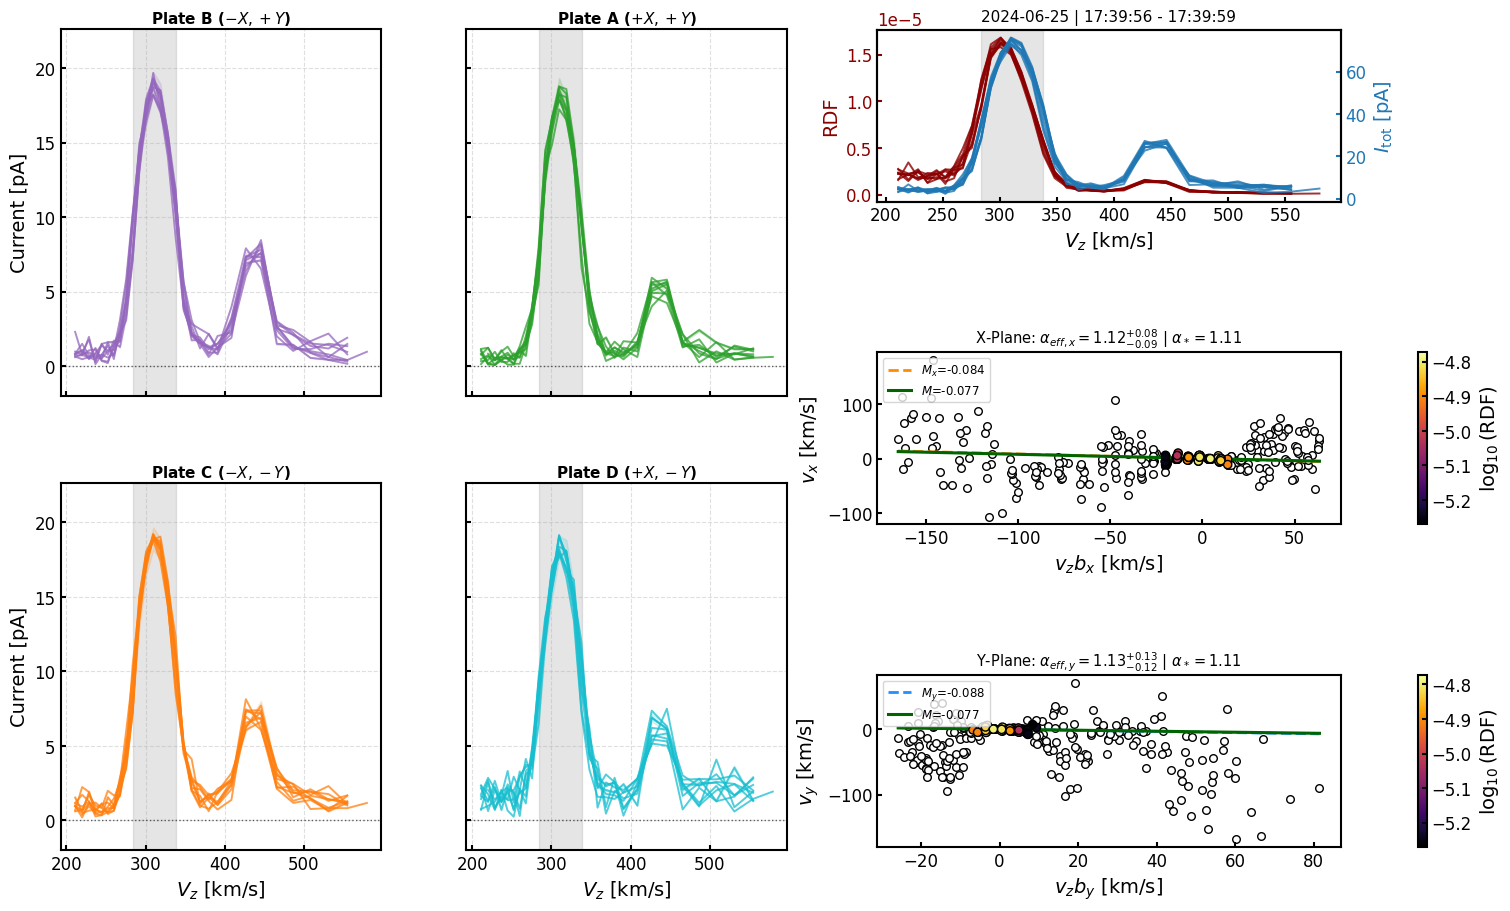

In [14]:
import os
from functions.supporting_plots import plot_spc_diagnostic_with_plates

date_folder = str(block_time)[:10]
plot_dir = f'test/5D_2/{date_folder}'
os.makedirs(plot_dir, exist_ok=True)
safe_time = str(block_time).replace(':', '').replace('-', '').replace('T', '_')
plot_spc_diagnostic_with_plates(block, valid_idx, block_time, 
                        vzbx_fit, vx_fit, var_x_array,
                        vzby_fit, vy_fit, var_y_array,
                        block_nvec_avg, update_dict,
                        show=True)


In [15]:
all_results[-1]

{'Nx': np.float64(0.6393767105583607),
 'Ny': np.float64(-0.24360244881054802),
 'Nz': np.float64(0.7292840797172763),
 'Bx': np.float64(50.342230837754336),
 'By': np.float64(-19.177837056692887),
 'Bz': np.float64(57.41836124233013),
 'B_var_x': np.float64(1.9662456568373297),
 'B_var_y': np.float64(3.8283450231637466),
 'B_var_z': np.float64(0.36759143617755147),
 'B_var_tot': np.float64(6.162182116178628),
 'B_x_flow_angle': np.float64(41.24163828784553),
 'B_y_flow_angle': np.float64(-18.47084368981793),
 'peak_azimuth': -0.50063157081604,
 'peak_elevation': 0.12758558988571167,
 'T_ani_avg': np.float64(1.1107993814033126),
 'T_ani_avg_delta_plus': np.float64(0.11637517989408952),
 'T_ani_avg_delta_minus': np.float64(0.09902773005922905),
 'T_ani_avg_delta_plus_log': np.float64(0.04327071477254784),
 'T_ani_avg_delta_minus_log': np.float64(0.040553122402008056),
 'T_ani_chi': np.float64(1.1219039527734571),
 'T_ani_chi_delta_plus': np.float64(0.08360746104172967),
 'T_ani_chi_delt